1 | Parameters and the two-state system
wn = 25.13 rad/s = 4.00 Hz = 240 rpm
k  = 3.158e+04 N/m,  c = 251.3 N s/m,  m_u e = 0.125 kg m
massless limit: tau = c/k = 7.96 ms  -> first order, cannot oscillate
eig(A) = [-2.51327412+25.00676178j -2.51327412-25.00676178j]
Re -> decay 2.51 1/s, tau = 0.40 s;  Im -> f_d = 3.98 Hz
high-speed scale mu_e/m = 2.50 mm

2 | Free response


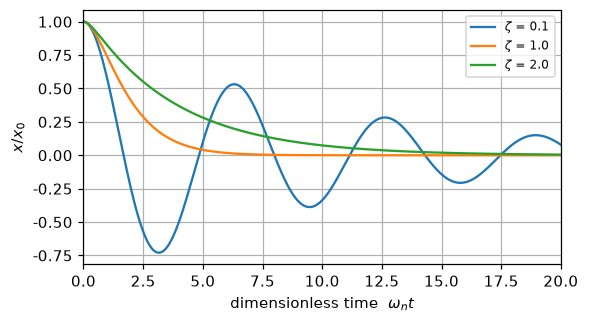

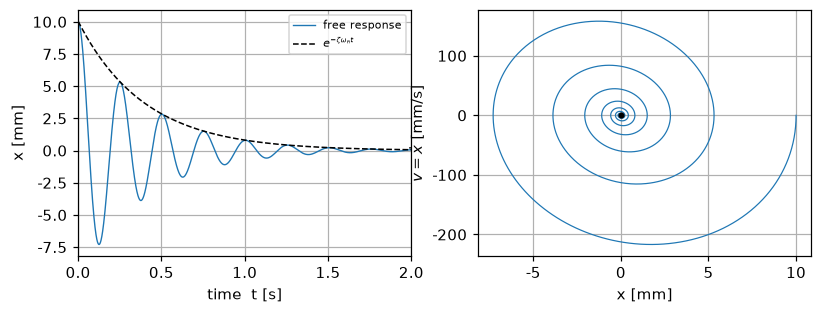

zeta = 0.1 rings at 3.98 Hz, envelope gone after ~2.0 s
zeta = 1 fastest return without overshoot; zeta = 2 slow creep (massless-like)


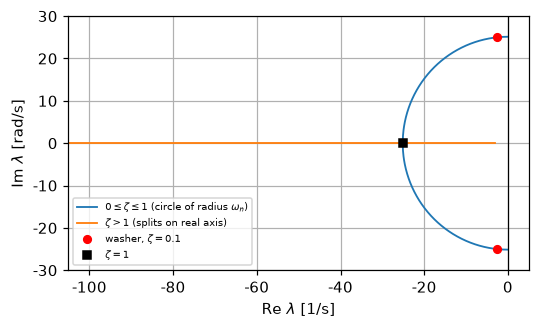

all Re(lambda) < 0 for c > 0 -> stable; max Re = -2.51 1/s

3 | Identification from a noisy free decay (0.15 mm noise)
true zeta    = 0.100
all peaks    (7): zeta = 0.079  (-21%)
strong peaks (4): zeta = 0.094  (-6%)
f_d from peak spacing = 3.98 Hz  (true 3.98 Hz)
peak picking catches positive noise -> late peaks inflated -> zeta biased low


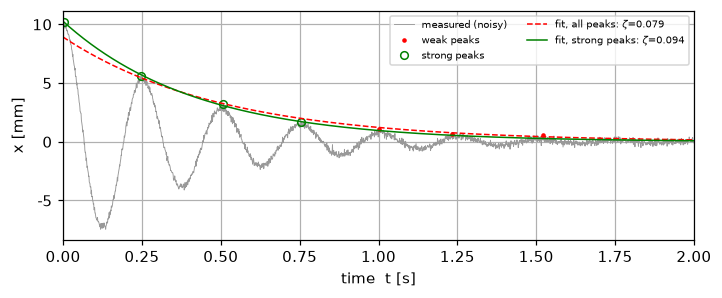


4 | Steady state, rotating unbalance
  240 rpm  r= 1.0  F0=   79.0 N  X=12.50 mm  phi=  -90.0 deg
 1200 rpm  r= 5.0  F0= 1973.9 N  X= 2.60 mm  phi= -177.6 deg
exact peak 12.56 mm at 242 rpm; plateau 2.50 mm
force ratio (1200/240)^2 = 25, motion ratio = 4.8  -> curve (C)


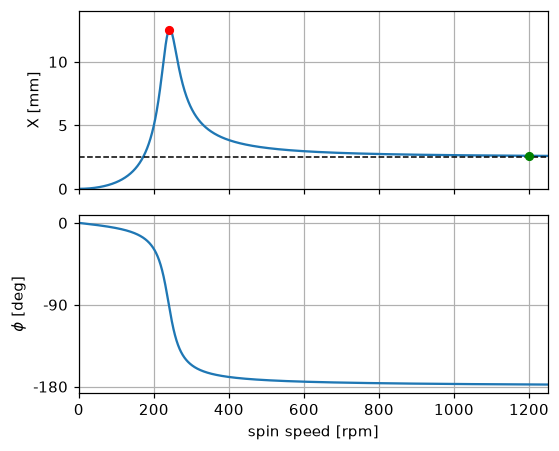


5 | Spin-up ramps (this is the slow part: the 40 rpm/s ramp lasts 32 s)


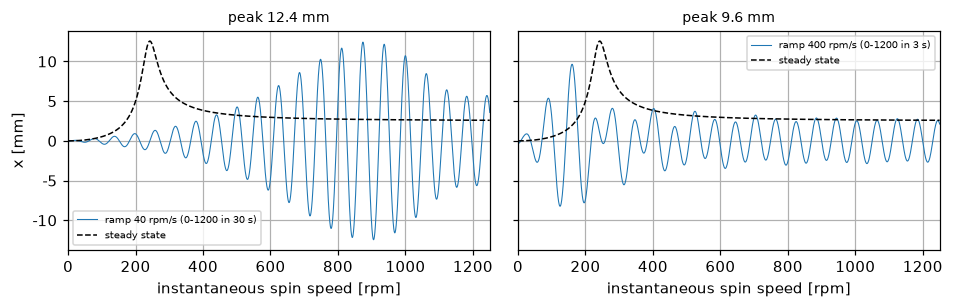

peak: 12.4 mm (slow) vs 9.6 mm (fast) -> answer (iii)
band ~ 2 zeta fn = 0.8 Hz = 48 rpm; time in band 1.20 s (slow) vs 0.12 s (fast)
build-up tau = 0.40 s; 95% of steady state needs 1.2 s

6 | Mass study at fixed k, c, m_u e
M = 50 kg: fn = 4.00 Hz = 240 rpm, zeta = 0.100, decay c/(2M) = 2.51 1/s, scale = 2.50 mm
          X_res ~ 12.5 mm (exact 12.6 mm), X(1200 rpm) = 2.60 mm -> clears
M = 30 kg: fn = 5.16 Hz = 310 rpm, zeta = 0.129, decay c/(2M) = 4.19 1/s, scale = 4.17 mm
          X_res ~ 16.1 mm (exact 16.3 mm), X(1200 rpm) = 4.45 mm -> HITS cabinet
M = 56 kg: fn = 3.78 Hz = 227 rpm, zeta = 0.094, decay c/(2M) = 2.24 1/s, scale = 2.23 mm
          X_res ~ 11.8 mm (exact 11.9 mm), X(1200 rpm) = 2.31 mm -> clears


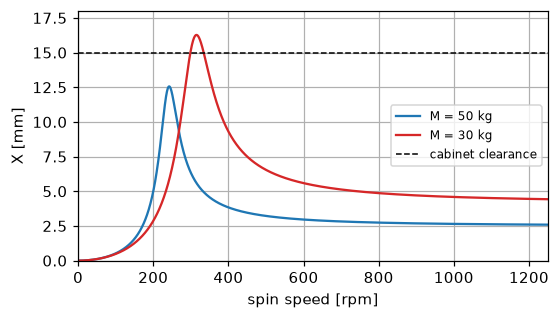

mass sets the scale mu_e/M ~ 1/M; zeta ~ 1/sqrt(M) cannot compensate

7 | Self-check against the lecture
OK   k [N/m]                got  31582.734   lecture  31580.000
OK   c [N s/m]              got    251.327   lecture    251.300
OK   tau_massless [ms]      got      7.958   lecture      7.960
OK   Re(lambda) [1/s]       got     -2.513   lecture     -2.510
OK   Im(lambda) [rad/s]     got     25.007   lecture     25.000
OK   f_d [Hz]               got      3.980   lecture      3.980
OK   zeta all peaks         got      0.079   lecture      0.079
OK   zeta strong peaks      got      0.094   lecture      0.094
OK   F0(240 rpm) [N]        got     78.957   lecture     79.000
OK   F0(1200 rpm) [N]       got   1973.921   lecture   1974.000
OK   X(240 rpm) [mm]        got     12.500   lecture     12.500
OK   X(1200 rpm) [mm]       got      2.602   lecture      2.600
OK   phi(1200 rpm) [deg]    got   -177.614   lecture   -178.000
OK   plateau [mm]           got      2.500   lecture      2.500

In [4]:
#!/usr/bin/env python3
# %% [1] Setup, parameters, derived quantities  (slides 6, 10-13)
"""
Why does a washing machine shake?  --  end-to-end demo (NMED 5XX, Unit 2, Lecture 1)

Everything the lecture quotes, from one file:
  * state matrix, eigenvalues, massless limit
  * free response (zeta = 0.1, 1, 2), phase portrait, eigenvalue locus
  * wn / zeta identified from a noisy free decay (peak log-fit)
  * steady-state amplitude and phase for a rotating unbalance
  * spin-up ramps (40 vs 400 rpm/s) integrated in the time domain
  * mass study: 50 kg design, 30 kg (concrete removed), 56 kg wet load
  * self-checks against every number printed on the slides

Usage
    python washer_demo.py                 # run all, write figures/*.pdf
    python washer_demo.py --show          # also open the figures on screen
    python washer_demo.py --fast          # coarser spin-up integration (quicker)
    python washer_demo.py --notebook      # also export washer_shake.ipynb
    jupytext --to notebook washer_demo.py # same export, if jupytext is installed

Requires: numpy, scipy, matplotlib.  SI units internally (kg, m, s); plots in mm.
The seven PDFs written to --outdir are exactly the files the beamer deck includes.
"""
import argparse
import json
import os
import sys

import numpy as np
import matplotlib


def _in_ipython():
    try:
        return get_ipython() is not None
    except NameError:
        return False


IN_NB = _in_ipython()
if not IN_NB and "--show" not in sys.argv:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.integrate import solve_ivp

OUTDIR, SAVE_FIGS, SHOW, MAX_STEP, EXPORT_NB = "figures", True, IN_NB, 1e-3, False
if not IN_NB and __name__ == "__main__":
    p = argparse.ArgumentParser(description="Washing-machine vibration demo")
    p.add_argument("--outdir", default=OUTDIR, help="figure directory (default: figures)")
    p.add_argument("--no-save", action="store_true", help="do not write figure files")
    p.add_argument("--show", action="store_true", help="display figures on screen")
    p.add_argument("--fast", action="store_true", help="max_step = 2e-3 in spin-up")
    p.add_argument("--notebook", nargs="?", const="washer_shake.ipynb", default=None,
                   metavar="PATH", help="also export this file as a Jupyter notebook")
    a = p.parse_args()
    OUTDIR, SAVE_FIGS, SHOW = a.outdir, not a.no_save, a.show
    MAX_STEP = 2e-3 if a.fast else 1e-3
    EXPORT_NB = a.notebook

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "axes.unicode_minus": False,
                     "figure.figsize": (7, 3), "savefig.bbox": "tight"})

# --- washer data (slide 6); fn and zeta are chosen, k and c are derived (slide 40) ---
m      = 50.0          # suspended mass incl. clump [kg]  ("M" in the slides)
fn     = 4.0           # natural frequency [Hz] = 240 rpm
zeta   = 0.10          # damping ratio [-]
mu_e   = 0.5 * 0.25    # unbalance m_u * e [kg m]
x0     = 10e-3         # initial push for the free-decay demos [m]
NOISE  = 0.15e-3       # sensor noise, standard deviation [m]
SEED   = 264           # reproduces the slide's zeta = 0.079 / 0.094
CLEAR  = 15.0          # tub-to-cabinet clearance [mm]

wn = 2 * np.pi * fn
k  = m * wn**2                  # k = M wn^2
c  = 2 * zeta * m * wn          # c = 2 zeta M wn
wd = wn * np.sqrt(1 - zeta**2)  # damped natural frequency

print("=" * 72)
print("1 | Parameters and the two-state system")
print("=" * 72)
print(f"wn = {wn:.2f} rad/s = {fn:.2f} Hz = {60*fn:.0f} rpm")
print(f"k  = {k:.4g} N/m,  c = {c:.4g} N s/m,  m_u e = {mu_e} kg m")
print(f"massless limit: tau = c/k = {1e3*c/k:.2f} ms  -> first order, cannot oscillate")

# %% [2] Core model helpers
def state_matrix(m=m, k=k, c=c):
    """x' = A x + b f with state (x, v)."""
    return np.array([[0.0, 1.0], [-k / m, -c / m]]), np.array([0.0, 1.0 / m])


def eig(m=m, k=k, c=c):
    return np.linalg.eigvals(state_matrix(m, k, c)[0])


def rhs_free(t, y, m=m, k=k, c=c):
    x, v = y
    return [v, (-c * v - k * x) / m]


def free_decay(t, m=m, k=k, c=c, x0=x0, v0=0.0):
    """Analytic underdamped free response (zeta < 1)."""
    wnl = np.sqrt(k / m)
    zl = c / (2 * m * wnl)
    wdl = wnl * np.sqrt(1 - zl**2)
    b = (v0 + zl * wnl * x0) / wdl
    return np.exp(-zl * wnl * t) * (x0 * np.cos(wdl * t) + b * np.sin(wdl * t))


def amp_phase(f_hz, m=m, k=k, c=c, mu_e=mu_e):
    """Steady state, rotating unbalance. Returns F0 [N], X [m], phi [deg] (arrays)."""
    w = 2 * np.pi * np.atleast_1d(np.asarray(f_hz, dtype=float))
    F0 = mu_e * w**2                              # force amplitude grows as w^2
    H = 1.0 / (k - m * w**2 + 1j * c * w)         # X / F0
    return F0, F0 * np.abs(H), np.degrees(np.angle(H))


def spinup(ramp_rpm_s, w_max=2 * np.pi * 20.0, max_step=None,
           m=m, k=k, c=c, mu_e=mu_e):
    """Time-domain spin-up. Force = mu_e (th'^2 sin th - th'' cos th), state (x, v, th)."""
    alpha = ramp_rpm_s / 60 * 2 * np.pi
    t_end = w_max / alpha + 2.0
    step = MAX_STEP if max_step is None else max_step

    def rhs(t, y):
        x, v, th = y
        om, al = (alpha * t, alpha) if alpha * t < w_max else (w_max, 0.0)
        F = mu_e * (om**2 * np.sin(th) - al * np.cos(th))
        return [v, (F - c * v - k * x) / m, om]

    s = solve_ivp(rhs, (0, t_end), [0.0, 0.0, 0.0],
                  max_step=step, rtol=1e-8, atol=1e-10)
    return s.y[2] * 60 / (2 * np.pi), s.y[0]      # instantaneous rpm, x [m]


def peak_of(m=m, k=k, c=c, mu_e=mu_e):
    """Exact peak of X(r) for rotating unbalance: r = 1/sqrt(1-2 zeta^2)."""
    wnl = np.sqrt(k / m)
    zl = c / (2 * m * wnl)
    r_pk = 1 / np.sqrt(1 - 2 * zl**2)
    return (mu_e / m) / (2 * zl * np.sqrt(1 - zl**2)), r_pk * wnl / (2 * np.pi)


FIGS = {}


def save(fig, name):
    """Register a figure and (optionally) write it to OUTDIR as PDF."""
    FIGS[name] = fig
    if SAVE_FIGS:
        os.makedirs(OUTDIR, exist_ok=True)
        fig.savefig(os.path.join(OUTDIR, name + ".pdf"))
    if SHOW:
        plt.show()
    return fig


A, b = state_matrix()
lam = eig()
print(f"eig(A) = {lam}")
print(f"Re -> decay {zeta*wn:.2f} 1/s, tau = {1/(zeta*wn):.2f} s;  Im -> f_d = {wd/(2*np.pi):.2f} Hz")
print(f"high-speed scale mu_e/m = {1e3*mu_e/m:.2f} mm")

# %% [3] Free response: damping regimes and phase portrait  (slides 14-15)
print("\n" + "=" * 72)
print("2 | Free response")
print("=" * 72)

fig, ax = plt.subplots(figsize=(5.6, 3.0))
tt = np.linspace(0, 20 / wn, 2000)
for z in (0.1, 1.0, 2.0):
    s = solve_ivp(rhs_free, (0, tt[-1]), [x0, 0.0], args=(m, k, 2 * z * m * wn),
                  dense_output=True, rtol=1e-9, atol=1e-12)
    ax.plot(wn * tt, s.sol(tt)[0] / x0, label=f"$\\zeta$ = {z}")
ax.set(xlabel="dimensionless time  $\\omega_n t$", ylabel="$x/x_0$", xlim=(0, 20))
ax.legend(fontsize=8)
save(fig, "fig_free_regimes")

t = np.linspace(0, 2, 4000)
s = solve_ivp(rhs_free, (0, 2), [x0, 0.0], dense_output=True, rtol=1e-9, atol=1e-12)
xx, vv = s.sol(t)
env = x0 * np.exp(-zeta * wn * t) * np.sqrt(1 + (zeta * wn / wd)**2)

fig, ax = plt.subplots(1, 2, figsize=(8.6, 2.9))
ax[0].plot(t, 1e3 * xx, lw=0.9, label="free response")
ax[0].plot(t, 1e3 * env, "k--", lw=1, label="$e^{-\\zeta\\omega_n t}$")
ax[0].set(xlabel="time  t [s]", ylabel="x [mm]", xlim=(0, 2))
ax[0].legend(fontsize=7)
ax[1].plot(1e3 * xx, 1e3 * vv, lw=0.8)
ax[1].plot(0, 0, "k.", ms=6)
ax[1].set(xlabel="x [mm]", ylabel="$v=\\dot x$ [mm/s]")
save(fig, "fig_phase_portrait")
print(f"zeta = 0.1 rings at {wd/(2*np.pi):.2f} Hz, envelope gone after ~{5/(zeta*wn):.1f} s")
print("zeta = 1 fastest return without overshoot; zeta = 2 slow creep (massless-like)")

# %% [4] Eigenvalue locus versus damping; stability  (slide 16)
fig, ax = plt.subplots(figsize=(5.4, 3.0))
z1 = np.linspace(0, 1, 400)
re, im = -z1 * wn, wn * np.sqrt(1 - z1**2)
ax.plot(re, im, "C0", lw=1.2)
ax.plot(re, -im, "C0", lw=1.2, label="$0\\leq\\zeta\\leq1$ (circle of radius $\\omega_n$)")
z2 = np.linspace(1, 4, 200)
r1 = -z2 * wn + wn * np.sqrt(z2**2 - 1)
r2 = -z2 * wn - wn * np.sqrt(z2**2 - 1)
ax.plot(r1, np.zeros_like(r1), "C1", lw=1.2, label="$\\zeta>1$ (splits on real axis)")
ax.plot(r2, np.zeros_like(r2), "C1", lw=1.2)
ax.plot(lam.real, lam.imag, "ro", ms=5, label="washer, $\\zeta=0.1$")
ax.plot(-wn, 0, "ks", ms=5, label="$\\zeta=1$")
ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="Re $\\lambda$ [1/s]", ylabel="Im $\\lambda$ [rad/s]",
       xlim=(-105, 5), ylim=(-30, 30))
ax.legend(fontsize=6.5, loc="lower left")
save(fig, "fig_eigs")
print(f"all Re(lambda) < 0 for c > 0 -> stable; max Re = {lam.real.max():.2f} 1/s")

# %% [5] Identify wn and zeta from a noisy free decay  (slide 17)
print("\n" + "=" * 72)
print("3 | Identification from a noisy free decay (0.15 mm noise)")
print("=" * 72)
fs = 1000.0
tm = np.arange(0, 2.0, 1 / fs)
x_true = free_decay(tm)
x_meas = x_true + np.random.default_rng(SEED).normal(0, NOISE, tm.size)
dist = int(0.8 * fs / fn)                 # at most one peak per damped period


def fit_peaks(height):
    pk, _ = find_peaks(x_meas, distance=dist, height=height)
    slope, icpt = np.polyfit(tm[pk], np.log(x_meas[pk]), 1)   # slope = -zeta*wn
    return -slope / wn, np.exp(icpt), pk


z_all, X0_all, pk_all = fit_peaks(0.5e-3)   # all peaks
z_str, X0_str, pk_str = fit_peaks(1.5e-3)   # strong peaks only
fd_est = 1 / np.mean(np.diff(tm[pk_str]))
weak = np.setdiff1d(pk_all, pk_str)

print(f"true zeta    = {zeta:.3f}")
print(f"all peaks    ({pk_all.size}): zeta = {z_all:.3f}  ({100*(z_all/zeta-1):+.0f}%)")
print(f"strong peaks ({pk_str.size}): zeta = {z_str:.3f}  ({100*(z_str/zeta-1):+.0f}%)")
print(f"f_d from peak spacing = {fd_est:.2f} Hz  (true {wd/(2*np.pi):.2f} Hz)")
print("peak picking catches positive noise -> late peaks inflated -> zeta biased low")

fig, ax = plt.subplots(figsize=(7.4, 2.7))
ax.plot(tm, 1e3 * x_meas, lw=0.6, color="0.6", label="measured (noisy)")
ax.plot(tm[weak], 1e3 * x_meas[weak], "r.", ms=4, label="weak peaks")
ax.plot(tm[pk_str], 1e3 * x_meas[pk_str], "go", ms=5, mfc="none", label="strong peaks")
ax.plot(tm, 1e3 * X0_all * np.exp(-z_all * wn * tm), "r--", lw=1,
        label=f"fit, all peaks: $\\zeta$={z_all:.3f}")
ax.plot(tm, 1e3 * X0_str * np.exp(-z_str * wn * tm), "g-", lw=1,
        label=f"fit, strong peaks: $\\zeta$={z_str:.3f}")
ax.set(xlabel="time  t [s]", ylabel="x [mm]", xlim=(0, 2))
ax.legend(fontsize=6.5, ncol=2)
save(fig, "fig_identify")

# %% [6] Forced response: amplitude and phase versus spin speed  (slides 19-25)
print("\n" + "=" * 72)
print("4 | Steady state, rotating unbalance")
print("=" * 72)
rpm = np.linspace(0.5, 1250, 2500)
F0, X, phi = amp_phase(rpm / 60)
for s_rpm in (240, 1200):
    F, XX, ph = amp_phase(s_rpm / 60)
    print(f"{s_rpm:5d} rpm  r={s_rpm/240:4.1f}  F0={F[0]:7.1f} N  "
          f"X={1e3*XX[0]:5.2f} mm  phi={ph[0]:7.1f} deg")
X_pk, f_pk = peak_of()
print(f"exact peak {1e3*X_pk:.2f} mm at {60*f_pk:.0f} rpm; plateau {1e3*mu_e/m:.2f} mm")
print(f"force ratio (1200/240)^2 = 25, motion ratio = "
      f"{amp_phase(4.0)[1][0]/amp_phase(20.0)[1][0]:.1f}  -> curve (C)")

fig, ax = plt.subplots(2, 1, figsize=(5.2, 4.2), sharex=True)
ax[0].plot(rpm, 1e3 * X)
ax[0].axhline(1e3 * mu_e / m, ls="--", c="k", lw=1)
ax[0].plot(240, 1e3 * amp_phase(4.0)[1][0], "ro", ms=5)
ax[0].plot(1200, 1e3 * amp_phase(20.0)[1][0], "go", ms=5)
ax[0].set(ylabel="X [mm]", ylim=(0, 14))
ax[1].plot(rpm, phi)
ax[1].set(ylabel="$\\phi$ [deg]", xlabel="spin speed [rpm]",
          yticks=[0, -90, -180], xlim=(0, 1250))
fig.tight_layout()
save(fig, "fig_unbalance")

# %% [7] Spin-up: resonance needs time to build  (slides 26-27, 38-39)
print("\n" + "=" * 72)
print("5 | Spin-up ramps (this is the slow part: the 40 rpm/s ramp lasts 32 s)")
print("=" * 72)
band_rpm = 60 * 2 * zeta * fn
peaks = {}
fig, axs = plt.subplots(1, 2, figsize=(8.8, 2.9), sharey=True)
for ax_, rate, dur in zip(axs, (40, 400), (30, 3)):
    r_inst, xr = spinup(rate)
    peaks[rate] = 1e3 * np.max(np.abs(xr))
    ax_.plot(r_inst, 1e3 * xr, lw=0.7, label=f"ramp {rate} rpm/s (0-1200 in {dur} s)")
    ax_.plot(rpm, 1e3 * X, "k--", lw=1, label="steady state")
    ax_.set(xlabel="instantaneous spin speed [rpm]", xlim=(0, 1250))
    ax_.set_title(f"peak {peaks[rate]:.1f} mm", fontsize=9)
    ax_.legend(fontsize=6.5)
axs[0].set_ylabel("x [mm]")
fig.tight_layout()
save(fig, "fig_spinup")
print(f"peak: {peaks[40]:.1f} mm (slow) vs {peaks[400]:.1f} mm (fast) -> answer (iii)")
print(f"band ~ 2 zeta fn = {2*zeta*fn:.1f} Hz = {band_rpm:.0f} rpm; "
      f"time in band {band_rpm/40:.2f} s (slow) vs {band_rpm/400:.2f} s (fast)")
print(f"build-up tau = {1/(zeta*wn):.2f} s; 95% of steady state needs {3/(zeta*wn):.1f} s")

# %% [8] Mass study: 50 kg design, 30 kg without concrete, 56 kg wet load  (slides 29, 34-36)
print("\n" + "=" * 72)
print("6 | Mass study at fixed k, c, m_u e")
print("=" * 72)
results = {}
for mp in (50.0, 30.0, 56.0):
    wnp = np.sqrt(k / mp)
    zp = c / (2 * mp * wnp)
    scale = mu_e / mp
    xpk, fpk = peak_of(m=mp)
    _, x1200, _ = amp_phase(20.0, m=mp)
    results[mp] = dict(fn=wnp / (2 * np.pi), zeta=zp, scale=scale,
                       xpk=xpk, fpk=fpk, x1200=x1200[0], decay=c / (2 * mp))
    print(f"M = {mp:.0f} kg: fn = {wnp/(2*np.pi):.2f} Hz = {60*wnp/(2*np.pi):.0f} rpm, "
          f"zeta = {zp:.3f}, decay c/(2M) = {c/(2*mp):.2f} 1/s, scale = {1e3*scale:.2f} mm")
    print(f"          X_res ~ {1e3*scale/(2*zp):.1f} mm (exact {1e3*xpk:.1f} mm), "
          f"X(1200 rpm) = {1e3*x1200[0]:.2f} mm -> "
          f"{'HITS cabinet' if 1e3*xpk > CLEAR else 'clears'}")

fig, ax = plt.subplots(figsize=(5.2, 3.0))
for mp, col in ((50.0, "C0"), (30.0, "C3")):
    _, xp, _ = amp_phase(rpm / 60, m=mp)
    ax.plot(rpm, 1e3 * xp, col, label=f"M = {mp:.0f} kg")
ax.axhline(CLEAR, ls="--", c="k", lw=1, label="cabinet clearance")
ax.set(xlabel="spin speed [rpm]", ylabel="X [mm]", xlim=(0, 1250), ylim=(0, 18))
ax.legend(fontsize=8)
fig.tight_layout()
save(fig, "fig_inclass")
print("mass sets the scale mu_e/M ~ 1/M; zeta ~ 1/sqrt(M) cannot compensate")

# %% [9] Self-check against every number quoted in the slides
print("\n" + "=" * 72)
print("7 | Self-check against the lecture")
print("=" * 72)
checks = {
    "k [N/m]":             (k,                              3.158e4, 1e-3),
    "c [N s/m]":           (c,                              251.3,   1e-3),
    "tau_massless [ms]":   (1e3 * c / k,                    7.96,    1e-2),
    "Re(lambda) [1/s]":    (lam.real[0],                   -2.51,    1e-2),
    "Im(lambda) [rad/s]":  (abs(lam.imag[0]),               25.0,    1e-2),
    "f_d [Hz]":            (wd / (2 * np.pi),               3.98,    1e-2),
    "zeta all peaks":      (z_all,                          0.079,   2e-2),
    "zeta strong peaks":   (z_str,                          0.094,   2e-2),
    "F0(240 rpm) [N]":     (amp_phase(4.0)[0][0],           79.0,    1e-2),
    "F0(1200 rpm) [N]":    (amp_phase(20.0)[0][0],          1974.0,  1e-2),
    "X(240 rpm) [mm]":     (1e3 * amp_phase(4.0)[1][0],     12.5,    1e-2),
    "X(1200 rpm) [mm]":    (1e3 * amp_phase(20.0)[1][0],    2.60,    1e-2),
    "phi(1200 rpm) [deg]": (amp_phase(20.0)[2][0],         -178.0,   3e-2),
    "plateau [mm]":        (1e3 * mu_e / m,                 2.5,     1e-6),
    "peak 50 kg [mm]":     (1e3 * results[50.0]["xpk"],     12.6,    1e-2),
    "fn 30 kg [Hz]":       (results[30.0]["fn"],            5.16,    1e-2),
    "zeta 30 kg":          (results[30.0]["zeta"],          0.129,   1e-2),
    "peak 30 kg [mm]":     (1e3 * results[30.0]["xpk"],     16.3,    1e-2),
    "X(1200) 30 kg [mm]":  (1e3 * results[30.0]["x1200"],   4.45,    1e-2),
    "fn 56 kg [Hz]":       (results[56.0]["fn"],            3.78,    1e-2),
    "zeta 56 kg":          (results[56.0]["zeta"],          0.094,   1e-2),
    "decay 56 kg [1/s]":   (results[56.0]["decay"],         2.24,    1e-2),
    "band [rpm]":          (band_rpm,                       48.0,    1e-6),
    "peak slow ramp [mm]": (peaks[40],                      12.4,    2e-2),
    "peak fast ramp [mm]": (peaks[400],                     9.7,     3e-2),
}
bad = []
for name, (got, want, tol) in checks.items():
    ok = abs(got - want) <= tol * max(1.0, abs(want))
    bad += [] if ok else [name]
    print(f"{'OK ' if ok else 'BAD'}  {name:22s} got {got:10.3f}   lecture {want:10.3f}")
assert not bad, f"mismatch: {bad}"
print(f"all {len(checks)} lecture numbers reproduced")

# %% [10] Export this file as a Jupyter notebook, and report
def export_notebook(path="washer_shake.ipynb", source=None):
    """Split this file on '# %%' markers into code cells and write a valid .ipynb."""
    src = source if source is not None else open(__file__, encoding="utf-8").read()
    chunks, cur, seen = [], [], False
    for line in src.splitlines(keepends=True):
        if line.startswith("# %%"):
            if seen:                           # start a new cell
                chunks.append("".join(cur))
                cur = [line]
            else:                              # shebang/preamble joins cell 1
                cur.append(line)
                seen = True
        else:
            cur.append(line)
    if cur:
        chunks.append("".join(cur))
    nb = {"cells": [{"cell_type": "code", "id": f"cell-{i}", "metadata": {},
                     "execution_count": None, "outputs": [],
                     "source": ch.rstrip("\n").splitlines(keepends=True)}
                    for i, ch in enumerate(chunks, 1)],
          "metadata": {"kernelspec": {"display_name": "Python 3", "language": "python",
                                      "name": "python3"},
                       "language_info": {"name": "python", "file_extension": ".py",
                                         "mimetype": "text/x-python",
                                         "codemirror_mode": {"name": "ipython", "version": 3},
                                         "nbconvert_exporter": "python",
                                         "pygments_lexer": "ipython3"}},
          "nbformat": 4, "nbformat_minor": 5}
    with open(path, "w", encoding="utf-8") as fh:
        json.dump(nb, fh, indent=1, ensure_ascii=False)
        fh.write("\n")
    print(f"notebook written: {path}  ({len(chunks)} code cells)")
    return path


if EXPORT_NB:
    export_notebook(EXPORT_NB)
if SAVE_FIGS:
    print(f"\n{len(FIGS)} figures written to {os.path.abspath(OUTDIR)}:")
    for name in FIGS:
        print("   " + name + ".pdf")
print("\ndone.")